In [1]:
# Loan Prediction using Machine Learning

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the datasets
train_dataset = pd.read_csv("Loan Train.csv")
test_dataset = pd.read_csv("Loan Test.csv")

# Display the first five rows
print("Training Dataset:")
display(train_dataset.head())

print("Testing Dataset:")
display(test_dataset.head())

Matplotlib is building the font cache; this may take a moment.


Training Dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


Testing Dataset:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [2]:
# Check dataset dimensions
print("Training Dataset Shape:", train_dataset.shape)
print("Testing Dataset Shape:", test_dataset.shape)

# Check column names and data types
print("\nTraining Dataset Information:")
train_dataset.info()

# Check statistical summary
print("\nStatistical Summary:")
display(train_dataset.describe())

# Check missing values
print("\nMissing Values in Training Dataset:")
print(train_dataset.isnull().sum())

print("\nMissing Values in Testing Dataset:")
print(test_dataset.isnull().sum())

Training Dataset Shape: (614, 13)
Testing Dataset Shape: (367, 12)

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Statistical S

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



Missing Values in Training Dataset:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Missing Values in Testing Dataset:
Loan_ID               0
Gender               11
Married               0
Dependents           10
Education             0
Self_Employed        23
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            5
Loan_Amount_Term      6
Credit_History       29
Property_Area         0
dtype: int64


Loan Status Counts:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


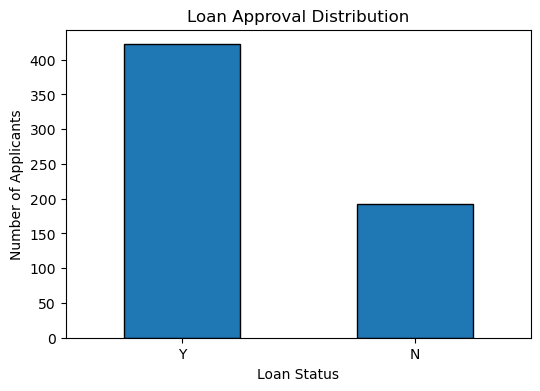

In [3]:
# Check loan approval distribution

print("Loan Status Counts:")
print(train_dataset['Loan_Status'].value_counts())

# Visualize loan approval distribution
plt.figure(figsize=(6, 4))

train_dataset['Loan_Status'].value_counts().plot(
    kind='bar',
    edgecolor='black'
)

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()


Loan Status based on Gender
Loan_Status    N    Y
Gender               
Female        37   75
Male         150  339


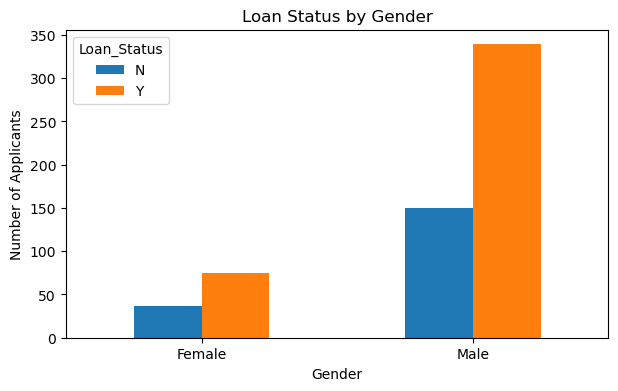


Loan Status based on Married
Loan_Status    N    Y
Married              
No            79  134
Yes          113  285


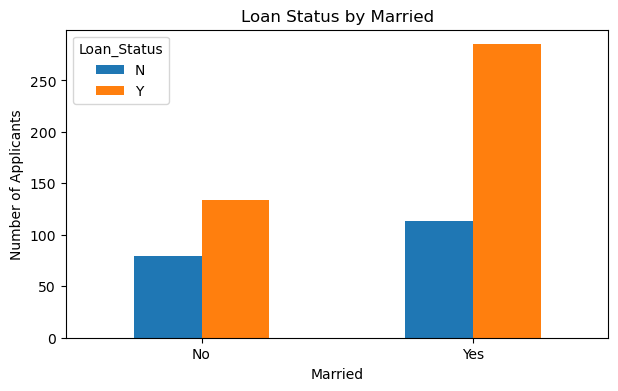


Loan Status based on Education
Loan_Status     N    Y
Education             
Graduate      140  340
Not Graduate   52   82


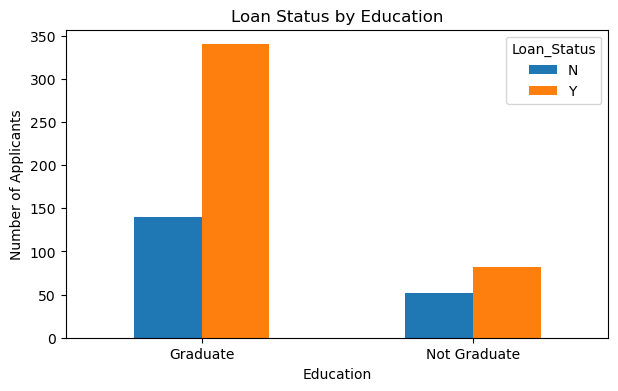


Loan Status based on Self_Employed
Loan_Status      N    Y
Self_Employed          
No             157  343
Yes             26   56


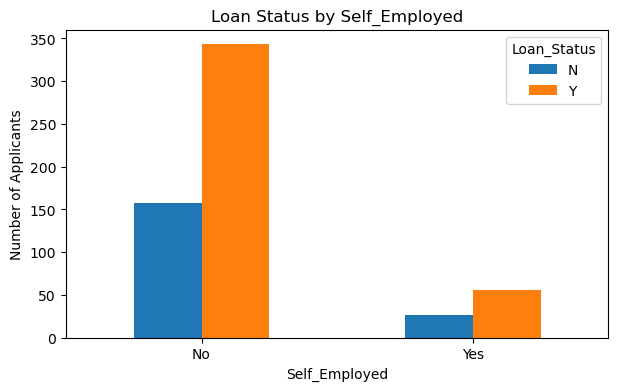


Loan Status based on Property_Area
Loan_Status     N    Y
Property_Area         
Rural          69  110
Semiurban      54  179
Urban          69  133


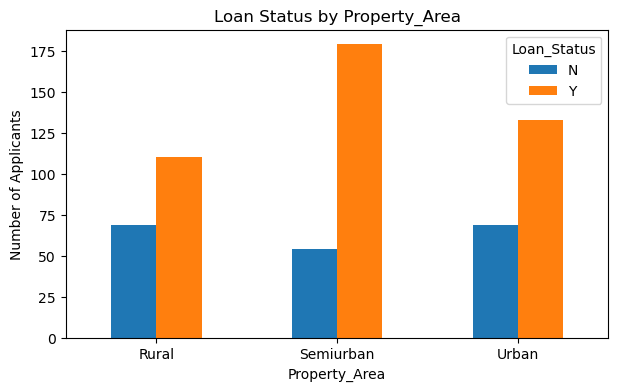

In [4]:
# Analyze loan status by categorical columns

categorical_columns = [
    'Gender',
    'Married',
    'Education',
    'Self_Employed',
    'Property_Area'
]

for column in categorical_columns:
    print("\nLoan Status based on", column)
    print(pd.crosstab(train_dataset[column], train_dataset['Loan_Status']))

    pd.crosstab(
        train_dataset[column],
        train_dataset['Loan_Status']
    ).plot(kind='bar', figsize=(7, 4))

    plt.title("Loan Status by " + column)
    plt.xlabel(column)
    plt.ylabel("Number of Applicants")
    plt.xticks(rotation=0)
    plt.show()

Numerical Data Summary:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
count,614.000000,614.000000,592.000000,600.00000
mean,5403.459283,1621.245798,146.412162,342.00000
std,6109.041673,2926.248369,85.587325,65.12041
min,150.000000,0.000000,9.000000,12.00000
25%,2877.500000,0.000000,100.000000,360.00000
50%,3812.500000,1188.500000,128.000000,360.00000
75%,5795.000000,2297.250000,168.000000,360.00000
max,81000.000000,41667.000000,700.000000,480.00000


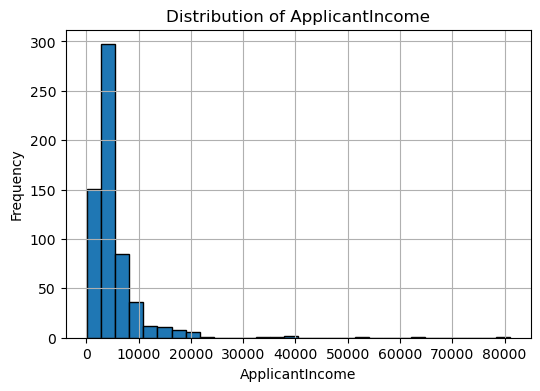

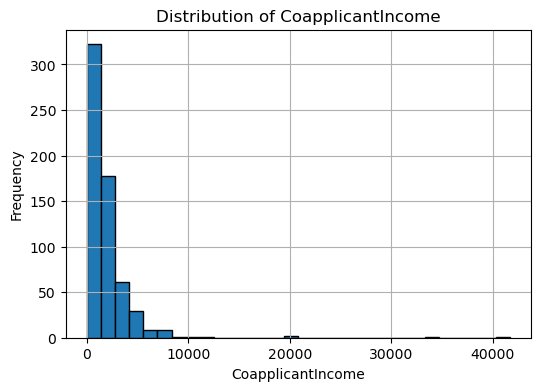

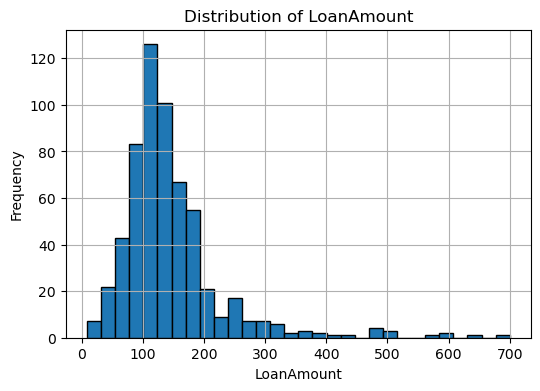

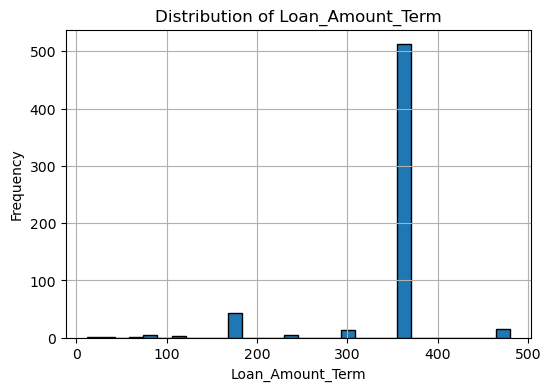

In [5]:
# Numerical column analysis

numerical_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

# Statistical summary
print("Numerical Data Summary:")
display(train_dataset[numerical_columns].describe())

# Histograms
for column in numerical_columns:
    plt.figure(figsize=(6, 4))

    train_dataset[column].hist(bins=30, edgecolor='black')

    plt.title("Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.show()

In [6]:
# Compare numerical values based on loan status

print("Average Numerical Values by Loan Status:")

display(
    train_dataset.groupby('Loan_Status')[numerical_columns].mean()
)

Average Numerical Values by Loan Status:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
Loan_Status,,,,
N,5446.078125,1877.807292,151.220994,344.064516
Y,5384.068720,1504.516398,144.294404,341.072464


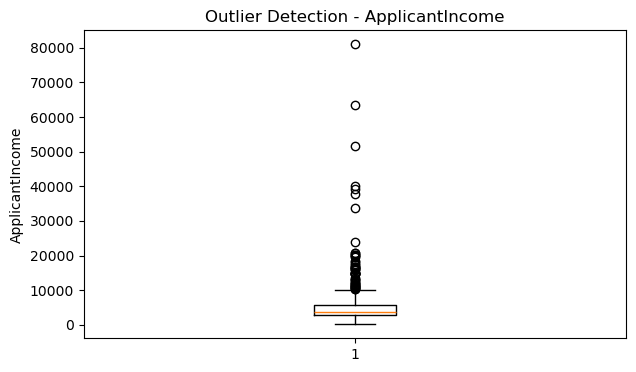

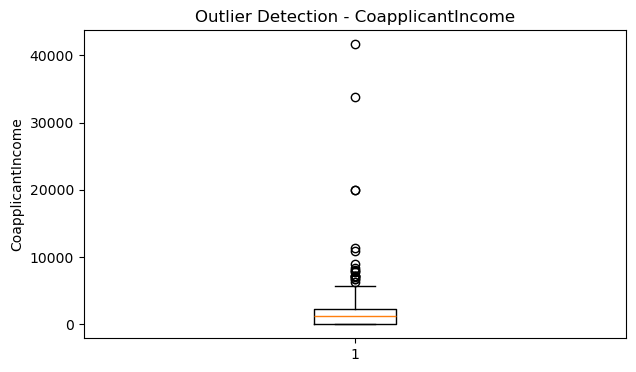

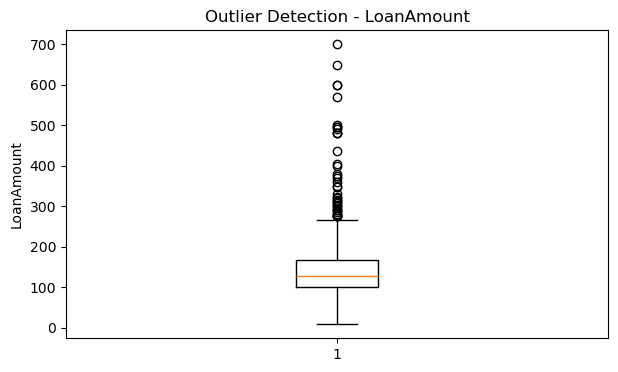

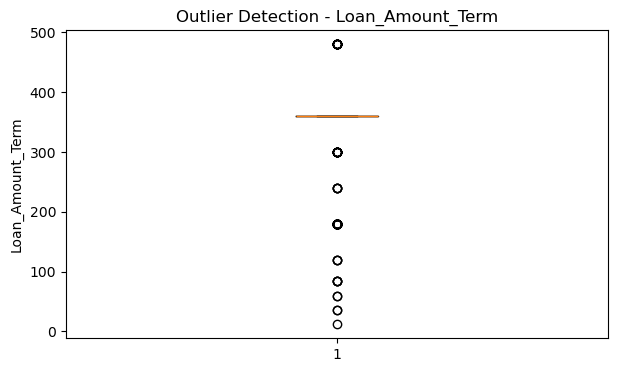

In [7]:
# Outlier Detection using Boxplots

numerical_columns = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term'
]

for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    plt.boxplot(train_dataset[column].dropna())

    plt.title("Outlier Detection - " + column)
    plt.ylabel(column)

    plt.show()

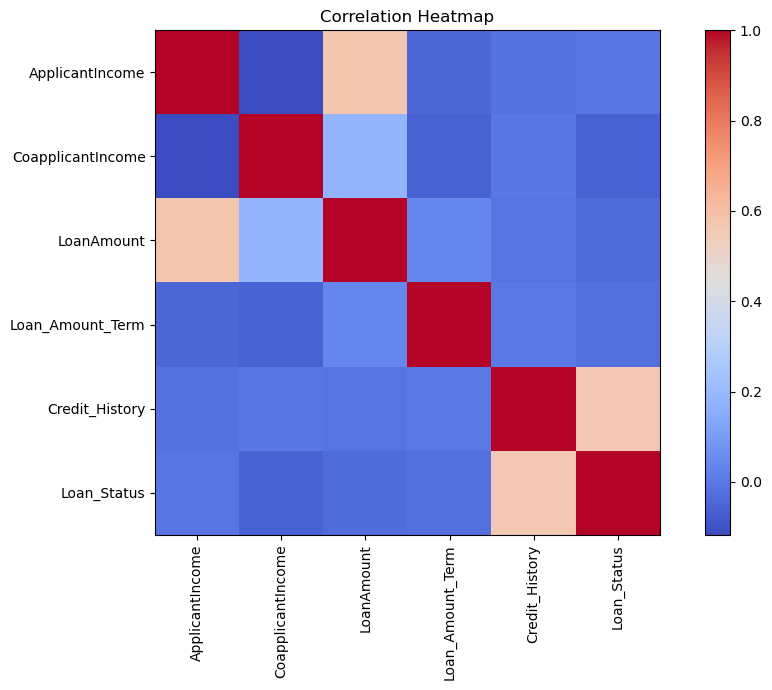

In [8]:
# Correlation Analysis

correlation_data = train_dataset.copy()

correlation_data['Loan_Status'] = (
    correlation_data['Loan_Status'].map({'Y': 1, 'N': 0})
)

correlation_matrix = correlation_data.corr(numeric_only=True)

plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap='coolwarm')
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [9]:
# Convert 3+ into 3 in Dependents column

train_dataset['Dependents'] = train_dataset['Dependents'].replace('3+', '3')
test_dataset['Dependents'] = test_dataset['Dependents'].replace('3+', '3')

# Convert Dependents into numeric values
train_dataset['Dependents'] = pd.to_numeric(
    train_dataset['Dependents'], errors='coerce'
)

test_dataset['Dependents'] = pd.to_numeric(
    test_dataset['Dependents'], errors='coerce'
)

print("Dependents column updated successfully!")

print(train_dataset['Dependents'].value_counts(dropna=False))

Dependents column updated successfully!
Dependents
0.0    345
1.0    102
2.0    101
3.0     51
NaN     15
Name: count, dtype: int64


In [10]:
# Convert Loan Status into numerical values

train_dataset['Loan_Status'] = train_dataset['Loan_Status'].map({
    'Y': 1,
    'N': 0
})

print(train_dataset['Loan_Status'].value_counts())

Loan_Status
1    422
0    192
Name: count, dtype: int64


In [11]:
# Feature Engineering

train_dataset['Total_Income'] = (
    train_dataset['ApplicantIncome'] +
    train_dataset['CoapplicantIncome']
)

test_dataset['Total_Income'] = (
    test_dataset['ApplicantIncome'] +
    test_dataset['CoapplicantIncome']
)

print("Total Income feature created successfully!")

display(train_dataset[
    ['ApplicantIncome', 'CoapplicantIncome', 'Total_Income']
].head())

Total Income feature created successfully!


,ApplicantIncome,CoapplicantIncome,Total_Income
0,5849,0.0,5849.0
1,4583,1508.0,6091.0
2,3000,0.0,3000.0
3,2583,2358.0,4941.0
4,6000,0.0,6000.0


In [12]:
# Separate input features and target variable

X = train_dataset.drop(
    ['Loan_ID', 'Loan_Status'], axis=1
)

y = train_dataset['Loan_Status']

# Prepare testing features
X_test = test_dataset.drop(['Loan_ID'], axis=1)

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)
print("Testing Features Shape:", X_test.shape)

# Display input features
display(X.head())

Input Features Shape: (614, 12)
Target Variable Shape: (614,)
Testing Features Shape: (367, 12)


,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Total_Income
0,Male,No,0.0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,5849.0
1,Male,Yes,1.0,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,6091.0
2,Male,Yes,0.0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,3000.0
3,Male,Yes,0.0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,4941.0
4,Male,No,0.0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,6000.0


In [14]:
from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Validation Features:", X_val.shape)

print("Training Target:", y_train.shape)
print("Validation Target:", y_val.shape)

Training Features: (491, 12)
Validation Features: (123, 12)
Training Target: (491,)
Validation Target: (123,)


In [15]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [16]:
# Numerical columns
numerical_features = [
    'ApplicantIncome',
    'CoapplicantIncome',
    'LoanAmount',
    'Loan_Amount_Term',
    'Credit_History',
    'Dependents',
    'Total_Income'
]

# Categorical columns
categorical_features = [
    'Gender',
    'Married',
    'Education',
    'Self_Employed',
    'Property_Area'
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Dependents', 'Total_Income']
Categorical Features: ['Gender', 'Married', 'Education', 'Self_Employed', 'Property_Area']


In [17]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_features),
    ('cat', categorical_transformer, categorical_features)
])

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [19]:
# Define Machine Learning models

models = []

models.append(('Logistic Regression', LogisticRegression(max_iter=1000)))
models.append(('Linear Discriminant Analysis', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('Decision Tree', DecisionTreeClassifier(random_state=42)))
models.append(('Naive Bayes', GaussianNB()))
models.append(('SVM', SVC()))

print("Six Machine Learning models are ready!")

Six Machine Learning models are ready!


In [20]:
# Compare Machine Learning models

results = []
names = []

scoring = 'accuracy'

kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in models:

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    cv_results = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring
    )

    results.append(cv_results)
    names.append(name)

    print(
        name,
        ": Mean Accuracy =",
        round(cv_results.mean() * 100, 2),
        "%"
    )

Logistic Regression : Mean Accuracy = 79.62 %
Linear Discriminant Analysis : Mean Accuracy = 79.83 %
KNN : Mean Accuracy = 77.19 %
Decision Tree : Mean Accuracy = 70.26 %
Naive Bayes : Mean Accuracy = 77.38 %
SVM : Mean Accuracy = 79.22 %


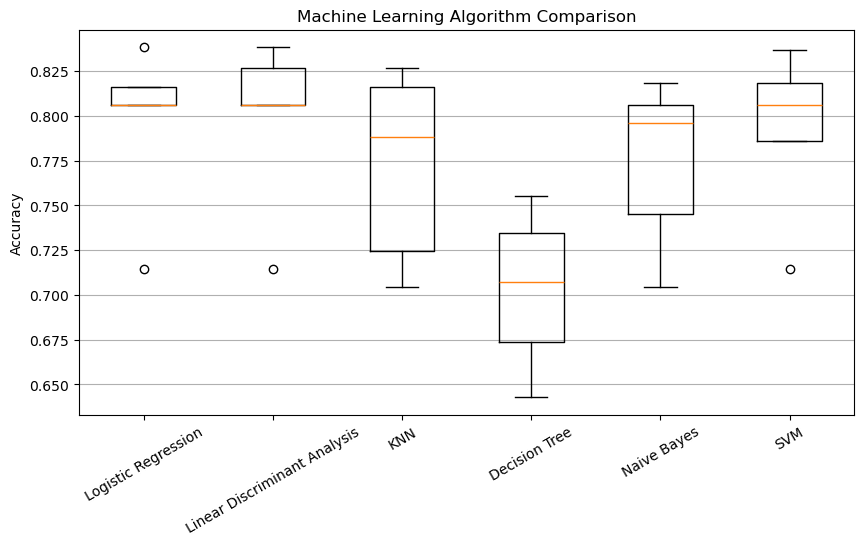

In [22]:
# Compare model accuracy using boxplot

plt.figure(figsize=(10, 5))

plt.boxplot(results, tick_labels=names)

plt.title("Machine Learning Algorithm Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.grid(axis='y')

plt.show()

In [23]:
# Evaluate all six Machine Learning models

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

for name, model in models:

    # Create pipeline
    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train model
    model_pipeline.fit(X_train, y_train)

    # Predict validation data
    y_pred = model_pipeline.predict(X_val)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)

    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_val, y_pred,
        zero_division=0
    ))


Model: Logistic Regression
Accuracy: 86.18 %
              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Model: Linear Discriminant Analysis
Accuracy: 86.18 %
              precision    recall  f1-score   support

           0       0.96      0.58      0.72        38
           1       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Model: KNN
Accuracy: 86.99 %
              precision    recall  f1-score   support

           0       0.92      0.63      0.75        38
           1       0.86      0.98      0.91        85

    accuracy                           0.87       1

In [24]:
# Display model comparison

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        by='F1 Score',
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
2,KNN,0.869919,0.855670,0.976471,0.912088
0,Logistic Regression,0.861789,0.840000,0.988235,0.908108
1,Linear Discriminant Analysis,0.861789,0.840000,0.988235,0.908108
5,SVM,0.845528,0.823529,0.988235,0.898396
4,Naive Bayes,0.845528,0.836735,0.964706,0.896175
3,Decision Tree,0.747967,0.846154,0.776471,0.809816


In [25]:
from sklearn.model_selection import GridSearchCV

# Create KNN pipeline
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

# Define parameter values
knn_parameters = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__p': [1, 2]
}

# Grid Search
knn_grid = GridSearchCV(
    knn_pipeline,
    knn_parameters,
    cv=kfold,
    scoring='f1_macro',
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN Parameters:", knn_grid.best_params_)
print("Best KNN CV Score:", knn_grid.best_score_)

Best KNN Parameters: {'classifier__n_neighbors': 15, 'classifier__p': 2, 'classifier__weights': 'uniform'}
Best KNN CV Score: 0.7074062175041016


In [26]:
# Create SVM pipeline

svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC())
])

# Define parameter values

svm_parameters = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto']
}

# Grid Search

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_parameters,
    cv=kfold,
    scoring='f1_macro',
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:", svm_grid.best_params_)
print("Best SVM CV Score:", svm_grid.best_score_)

Best SVM Parameters: {'classifier__C': 10, 'classifier__gamma': 'auto', 'classifier__kernel': 'rbf'}
Best SVM CV Score: 0.7127508348985162


In [27]:
# Evaluate tuned KNN and SVM

best_models = {
    'Tuned KNN': knn_grid.best_estimator_,
    'Tuned SVM': svm_grid.best_estimator_
}

for name, model in best_models.items():

    # Predict validation data
    y_pred = model.predict(X_val)

    print("\nModel:", name)

    print("Accuracy:",
          round(accuracy_score(y_val, y_pred) * 100, 2), "%")

    print("\nClassification Report:")
    print(classification_report(
        y_val, y_pred,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_pred))


Model: Tuned KNN
Accuracy: 84.55 %

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.53      0.68        38
           1       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123

Confusion Matrix:
[[20 18]
 [ 1 84]]

Model: Tuned SVM
Accuracy: 85.37 %

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.58      0.71        38
           1       0.84      0.98      0.90        85

    accuracy                           0.85       123
   macro avg       0.88      0.78      0.81       123
weighted avg       0.86      0.85      0.84       123

Confusion Matrix:
[[22 16]
 [ 2 83]]


In [28]:
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

In [29]:
# Define ensemble models

ensemble_models = []

ensemble_models.append((
    'Random Forest',
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
))

ensemble_models.append((
    'AdaBoost',
    AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    )
))

ensemble_models.append((
    'Gradient Boosting',
    GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    )
))

ensemble_models.append((
    'Extra Trees',
    ExtraTreesClassifier(
        n_estimators=100,
        random_state=42
    )
))

print("Four Ensemble Models are ready!")

Four Ensemble Models are ready!


In [30]:
# Train and evaluate ensemble models

ensemble_results = []

for name, model in ensemble_models:

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train model
    model_pipeline.fit(X_train, y_train)

    # Predict validation data
    y_pred = model_pipeline.predict(X_val)

    # Calculate metrics
    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)

    ensemble_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_val, y_pred,
        zero_division=0
    ))


Model: Random Forest
Accuracy: 84.55 %
              precision    recall  f1-score   support

           0       0.81      0.66      0.72        38
           1       0.86      0.93      0.89        85

    accuracy                           0.85       123
   macro avg       0.83      0.79      0.81       123
weighted avg       0.84      0.85      0.84       123


Model: AdaBoost
Accuracy: 84.55 %
              precision    recall  f1-score   support

           0       0.83      0.63      0.72        38
           1       0.85      0.94      0.89        85

    accuracy                           0.85       123
   macro avg       0.84      0.79      0.81       123
weighted avg       0.84      0.85      0.84       123


Model: Gradient Boosting
Accuracy: 82.11 %
              precision    recall  f1-score   support

           0       0.77      0.61      0.68        38
           1       0.84      0.92      0.88        85

    accuracy                           0.82       123
   macro 

In [31]:
# Compare ensemble model performance

ensemble_df = pd.DataFrame(ensemble_results)

display(
    ensemble_df.sort_values(
        by='F1 Score',
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
1,AdaBoost,0.845528,0.851064,0.941176,0.893855
0,Random Forest,0.845528,0.858696,0.929412,0.892655
2,Gradient Boosting,0.821138,0.838710,0.917647,0.876404
3,Extra Trees,0.796748,0.826087,0.894118,0.858757


In [32]:
# Compare all models using Macro F1 Score

from sklearn.metrics import f1_score

all_models = models + ensemble_models

macro_results = []

for name, model in all_models:

    model_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    model_pipeline.fit(X_train, y_train)

    y_pred = model_pipeline.predict(X_val)

    macro_f1 = f1_score(y_val, y_pred, average='macro')
    accuracy = accuracy_score(y_val, y_pred)

    macro_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Macro F1 Score': macro_f1
    })

macro_df = pd.DataFrame(macro_results)

display(
    macro_df.sort_values(
        by='Macro F1 Score',
        ascending=False
    )
)

,Model,Accuracy,Macro F1 Score
2,KNN,0.869919,0.831044
0,Logistic Regression,0.861789,0.814710
1,Linear Discriminant Analysis,0.861789,0.814710
6,Random Forest,0.845528,0.808647
7,AdaBoost,0.845528,0.805136
4,Naive Bayes,0.845528,0.797294
5,SVM,0.845528,0.788181
8,Gradient Boosting,0.821138,0.776438
9,Extra Trees,0.796748,0.748219
3,Decision Tree,0.747967,0.718161


In [33]:
# Final Model Training

from sklearn.neighbors import KNeighborsClassifier

final_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        weights='uniform',
        p=2
    ))
])

# Train using the complete training dataset
final_model.fit(X, y)

print("Final KNN Model Training Completed Successfully!")

Final KNN Model Training Completed Successfully!


In [34]:
# Predict loan status for test dataset

test_predictions = final_model.predict(X_test)

print("Loan Predictions Completed!")
print("Total Predictions:", len(test_predictions))

print("First 10 Predictions:")
print(test_predictions[:10])

Loan Predictions Completed!
Total Predictions: 367
First 10 Predictions:
[1 1 1 1 0 1 1 0 1 1]


In [35]:
# Convert numeric predictions into Y and N

loan_status = pd.Series(test_predictions).map({
    1: 'Y',
    0: 'N'
})

print("First 10 Loan Status Predictions:")
print(loan_status.head(10))

First 10 Loan Status Predictions:
0    Y
1    Y
2    Y
3    Y
4    N
5    Y
6    Y
7    N
8    Y
9    Y
dtype: object


In [36]:
# Create final submission dataframe

submission = pd.DataFrame({
    'Loan_ID': test_dataset['Loan_ID'],
    'Loan_Status': loan_status
})

# Save the CSV file
submission.to_csv('Loan_Prediction_Submission.csv', index=False)

print("Final CSV file saved successfully!")

display(submission.head())

Final CSV file saved successfully!


,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,N


In [37]:
# Read the saved CSV file
final_submission = pd.read_csv('Loan_Prediction_Submission.csv')

# Check the file
print("File Verification")
print("Total Rows:", final_submission.shape[0])
print("Total Columns:", final_submission.shape[1])

print("\nMissing Values:")
print(final_submission.isnull().sum())

print("\nLoan Status Distribution:")
print(final_submission['Loan_Status'].value_counts())

print("\nFirst 5 Records:")
display(final_submission.head())

print("\nLast 5 Records:")
display(final_submission.tail())

File Verification
Total Rows: 367
Total Columns: 2

Missing Values:
Loan_ID        0
Loan_Status    0
dtype: int64

Loan Status Distribution:
Loan_Status
Y    297
N     70
Name: count, dtype: int64

First 5 Records:


,Loan_ID,Loan_Status
0,LP001015,Y
1,LP001022,Y
2,LP001031,Y
3,LP001035,Y
4,LP001051,N



Last 5 Records:


,Loan_ID,Loan_Status
362,LP002971,Y
363,LP002975,Y
364,LP002980,Y
365,LP002986,Y
366,LP002989,Y


In [38]:
import joblib

# Save the trained model
joblib.dump(final_model, 'loan_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [39]:
import os

print(os.path.exists('loan_prediction_model.pkl'))

True


In [40]:
loaded_model = joblib.load('loan_prediction_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!
